## **Shallow water equations**

\begin{cases}
\dfrac{\partial \mathbf{u}(\mathbf{x},t)}{\partial t} = -\mathbf{u}(\mathbf{x},t) \cdot \nabla \mathbf{u}(\mathbf{x},t) - g \nabla h(\mathbf{x},t) - \nu \Delta^2 \mathbf{u}(\mathbf{x},t) - 2f \times u(\mathbf{x},t) \qquad &\mathrm{in } \ \Omega \times (0,T)
\\[7pt]
\dfrac{\partial h(\mathbf{x},t)}{\partial t} = -H \nabla \cdot \mathbf{u}(\mathbf{x},t) - \nabla \cdot (h(\mathbf{x},t) \mathbf{u}(\mathbf{x},t)) -\nu \Delta^2 h(\mathbf{x},t) + F(\mathbf{x},t) \qquad &\mathrm{in } \ \Omega \times (0,T)
\end{cases}


where $\Omega$ is the domain, $T > 0$ is the final time, $\mathbf{u}: \Omega \times [0,T] \to \mathbb{R}^2$ is the unknown velocity field, $h: \Omega \times [0,T] \to \mathbb{R}$ is the unknown height deviation of the horizontal pressure surface from its mean height, $F: \Omega \times [0,T] \to \mathbb{R}$ is a source term forcing annual and daily periodicity, $g$ is the gravity acceleration, $H$ is the mean height of the horizontal pressure surface, $f$ is the Coriolis coefficient and $\nu$ is the viscosity parameter

In [37]:
#IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc

from __future__ import print_function
from IPython.display import clear_output as clc

from the_well.data import WellDataset
from the_well.utils.download import well_download

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# my packages
from src.processdata import trajectory


Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [ ]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
#well_download(base_path="",dataset="planetswe",split="train")

In [ ]:
# LOAD THE DATASET

data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


In [40]:
# Define a function to plot the state of the system at a given time step
def plot_state(
    u, cmap, 
    colorbar = False, shrink = 1.0, extent = None, vmin = None, vmax = None
):
    fig = plt.imshow(u.reshape(Lx, Ly), extent = extent, cmap = cmap, vmin = vmin, vmax = vmax, origin = 'lower')
    if colorbar:
        plt.colorbar(fig, shrink = shrink)

# Define a function to plot the height field using a specific colormap
plot_height = lambda u: plot_state(u, cmap = "gist_earth")
# Define a function to plot the velocity field using a specific colormap
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

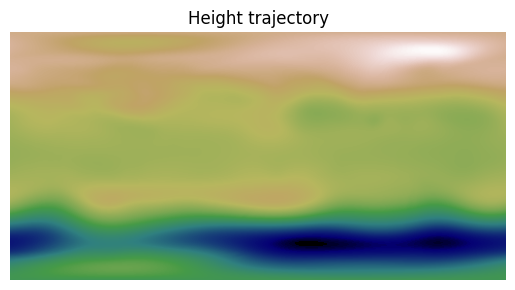

In [41]:
#Plot the trajectory of the height field for the first 50 time steps
whichtimes = np.arange(0,50)
trajectory(H[whichtimes], plot_height, title = "Height trajectory", fontsize = 12)

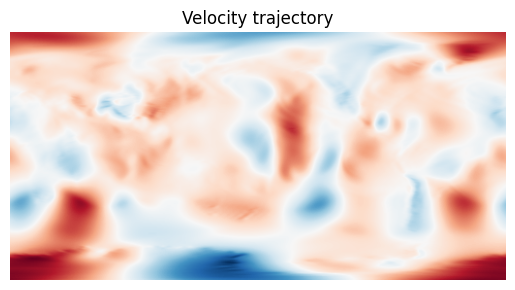

In [42]:
#Plot the trajectory of the velocity field for the first 50 time steps
whichtimes = np.arange(0,50)
trajectory(Utheta[whichtimes], plot_velocity, title = "Velocity trajectory", fontsize = 12)

## SENSOR DATA